# Leveraged Buyouts from Public Filings: Which U.S. Companies Go Private, a Classic LBO Screen versus Gradient Boosting, and LBO Models with Cash Sweeps, Returns Attribution and Monte Carlo IRR for Today's Candidates

In a **leveraged buyout** a financial sponsor buys a company with a small slice of equity and a large amount of debt, runs it for four to six years, and sells it. The debt is repaid from the company's own cash flow, so the sponsor's return comes from three sources: **EBITDA growth**, **multiple expansion** (selling at a higher EV/EBITDA than it paid) and **deleveraging** (the debt paid down with the company's cash). The classic LBO candidate has stable cash flows, low capital needs, little existing debt and a low valuation.

This notebook does three things with public data:

1. **Who actually goes private?** Every Schedule 13E-3 filed with the SEC since 2011 (the disclosure required when a public company is taken private by insiders, a sponsor or a controlling holder) is matched to the company's financial statements from XBRL. A **classic LBO screen** (a logistic regression on the textbook criteria) is compared with **gradient boosting** on a wider set of ratios, trained up to 2017 and tested on 2019–2022 fundamentals with going-private filings in 2020–2024.
2. **An LBO model** for today's top-ranked candidates: sources and uses, a term loan with mandatory amortisation and a cash sweep, senior notes, interest at current market rates, a five-year hold and an exit at the entry multiple, with IRR, money multiple and the attribution of the equity gain.
3. **Monte Carlo IRR:** revenue growth, margins and the exit multiple are simulated from each company's own history, giving the distribution of sponsor returns and the probability of losing money.

**Data.** SEC EDGAR full-index of filings (Schedule 13E-3); SEC XBRL frames API (annual financial statements and public float of every filer); FRED (SOFR, 10-year Treasury yield, ICE BofA US High Yield option-adjusted spread); Yahoo Finance (current market capitalisation of the candidates); SEC company tickers.

**Methods.** LBO model with sources and uses, term-loan amortisation, cash sweep and bullet notes; IRR, MOIC and value-creation attribution; logistic regression on textbook LBO criteria vs LightGBM; out-of-time testing with ROC AUC, precision–recall and top-decile capture; SHAP-style feature importance; Monte Carlo simulation of operating paths and exit multiples.

**Key output.** What distinguishes companies that went private; how much better than the textbook screen a machine-learning screen ranks them; a complete LBO model for the top candidate; and the distribution of IRRs for the top candidates.

## 1. The LBO model in one page

| Step | Assumption in this notebook |
|---|---|
| **Entry price** | market capitalisation × (1 + 30% premium) + net debt = enterprise value; fees 2% of enterprise value |
| **Debt** | the lowest of 6.0 × EBITDA, the amount that keeps EBITDA / interest ≥ 2.0 in year 1, and 70% of the enterprise value |
| **Tranches** | 65% term loan B at SOFR + 3.75%, 1% amortisation a year plus a 75% sweep of excess cash; 35% senior notes at the 10-year Treasury + the high-yield spread, repaid at exit |
| **Sponsor equity** | enterprise value + fees − debt |
| **Operations** | revenue growth = the company's median of the last three years (0–10%); EBITDA margin, capex and depreciation at their three-year medians; working capital 10% of the revenue increase; tax 25% of EBIT − interest |
| **Exit** | year 5 at the entry EV/EBITDA multiple; equity = exit EV − remaining debt + cash |

**Attribution of the equity gain** (exit equity − entry equity):
- **EBITDA growth** = (EBITDA at exit − EBITDA at entry) × entry multiple;
- **multiple expansion** = (exit multiple − entry multiple) × EBITDA at exit;
- **deleveraging** = net debt at entry − net debt at exit;
- **fees and premium** = the part of the entry price above the market value of the business, lost at entry.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import io
import re

import lightgbm as lgb
import yfinance as yf
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2026
rng = np.random.default_rng(SEED)
SEC_HEADERS = {"User-Agent": os.getenv("SEC_USER_AGENT", "").strip()}
if not SEC_HEADERS["User-Agent"]:
    raise RuntimeError(
        "SEC_USER_AGENT missing in .env (the SEC asks automated clients to"
        " identify themselves)."
    )
FIRST_CY, LAST_CY = 2010, 2025
INDEX_YEARS = range(2011, 2027)
# item: (taxonomy, tags in order of preference, period type)
CONCEPTS = {
    "rev": (
        "us-gaap",
        [
            "Revenues",
            "RevenueFromContractWithCustomerExcludingAssessedTax",
            "SalesRevenueNet",
        ],
        "D",
    ),
    "ebit": ("us-gaap", ["OperatingIncomeLoss"], "D"),
    "da": (
        "us-gaap",
        [
            "DepreciationDepletionAndAmortization",
            "DepreciationAndAmortization",
        ],
        "D",
    ),
    "cfo": ("us-gaap", ["NetCashProvidedByUsedInOperatingActivities"], "D"),
    "capex": ("us-gaap", ["PaymentsToAcquirePropertyPlantAndEquipment"], "D"),
    "interest": ("us-gaap", ["InterestExpense"], "D"),
    "ni": ("us-gaap", ["NetIncomeLoss"], "D"),
    "assets": ("us-gaap", ["Assets"], "I"),
    "cash": ("us-gaap", ["CashAndCashEquivalentsAtCarryingValue"], "I"),
    "debt": ("us-gaap", ["LongTermDebt", "LongTermDebtNoncurrent"], "I"),
    "eq": ("us-gaap", ["StockholdersEquity"], "I"),
    "float": ("dei", ["EntityPublicFloat"], "Q2I"),
}
# label: a Schedule 13E-3 filed within two calendar years after the
# fundamentals
HORIZON = 2
TRAIN_LAST, TEST_FIRST, TEST_LAST = 2017, 2019, 2022
PREMIUM, FEES, MAX_LEV, MIN_COVER, MAX_DEBT_EV = 0.30, 0.02, 6.0, 2.0, 0.70
TLB_SHARE, TLB_SPREAD, AMORT, SWEEP = 0.65, 0.0375, 0.01, 0.75
HOLD, TAX, NWC = 5, 0.25, 0.10
N_SIMS = 5000

print(
    f"lightgbm {lgb.__version__} · yfinance {yf.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

lightgbm 4.7.0 · yfinance 1.7.0 · run on 2026-11-11


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Data

**Going-private filings.** The EDGAR full-index lists every filing by form type each quarter. A Schedule 13E-3 (`SC 13E3`, amendments excluded) is filed by the company being taken private and by the buyers; matching the filer's identifier (CIK) to the companies with financial statements keeps the targets. Not every 13E-3 is a sponsor-backed LBO: management buyouts, squeeze-outs by a controlling holder and reverse splits to deregister also file one. All of them are the same economic event for the screen: the public shareholders are bought out.

**Financial statements.** The SEC frames API returns one concept for every filer and calendar year (annual flows, year-end balances; public float at mid-year), which gives the whole cross-section of U.S. listed companies without downloading company by company.

In [3]:
def sec_get(url):
    for attempt in range(4):
        r = requests.get(url, headers=SEC_HEADERS, timeout=180)
        if r.status_code == 200:
            return r
        if r.status_code == 404:
            return None
        time.sleep(2 + 3 * attempt)
    r.raise_for_status()


def fetch_13e3():
    rows = []
    pat = re.compile(
        r"^(SC 13E3)\s+(.+?)\s{2,}(\d+)\s+(\d{4}-\d{2}-\d{2})\s+(\S+)"
    )
    for y in INDEX_YEARS:
        for q in range(1, 5):
            r = sec_get(
                f"https://www.sec.gov/Archives/edgar/full-index/{y}/QTR{q}/form.idx"
            )
            if r is None:
                continue
            for line in r.text.splitlines():
                m = pat.match(line)
                if m:
                    rows.append(m.groups())
            time.sleep(0.2)
    return pd.DataFrame(
        rows, columns=["form", "name", "cik", "filed", "path"]
    ).astype({"cik": int})


def fetch_frames():
    out = []
    for item, (tax, tags, ptype) in CONCEPTS.items():
        for rank, tag in enumerate(tags):
            for cy in range(FIRST_CY, LAST_CY + 1):
                period = (
                    f"CY{cy}"
                    if ptype == "D"
                    else f"CY{cy}Q4I" if ptype == "I" else f"CY{cy}Q2I"
                )
                r = sec_get(
                    f"https://data.sec.gov/api/xbrl/frames/{tax}/{tag}/USD/{period}.json"
                )
                if r is None:
                    continue
                d = pd.DataFrame(r.json()["data"])[
                    ["cik", "entityName", "val"]
                ].assign(item=item, cy=cy, rank=rank)
                out.append(d)
                time.sleep(0.12)
    return pd.concat(out, ignore_index=True)


t0 = time.time()
GP_FILINGS = cached("sec_13e3_filings", fetch_13e3, max_age_hours=24 * 7)
FR = cached("sec_xbrl_frames", fetch_frames, max_age_hours=24 * 7)
GP_FILINGS["filed"] = pd.to_datetime(GP_FILINGS.filed)
FR = FR.sort_values("rank").drop_duplicates(["cik", "item", "cy"])
P = FR.pivot_table(
    index=["cik", "cy"], columns="item", values="val", aggfunc="first"
).reset_index()
names = FR.drop_duplicates("cik").set_index("cik").entityName
P["name"] = P.cik.map(names)
print(
    f"{len(GP_FILINGS):,} Schedule 13E-3 filings by"
    f" {GP_FILINGS.cik.nunique():,} filers, {GP_FILINGS.filed.min():%Y-%m} →"
    f" {GP_FILINGS.filed.max():%Y-%m} · {len(FR):,} XBRL frame values,"
    f" {P.cik.nunique():,} companies · {time.time() - t0:.0f} s"
)
GP_FILINGS.groupby(GP_FILINGS.filed.dt.year).size().rename(
    "filings"
).to_frame().T

815 Schedule 13E-3 filings by 705 filers, 2011-01 → 2026-11 · 1,030,602 XBRL frame values, 16,049 companies · 1 s


filed,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
filings,94,54,81,43,33,78,39,44,29,56,39,49,55,54,37,30


### Features and labels

Each company-year needs positive revenue (at least USD 50 million) and positive EBITDA (operating income + depreciation), because a buyout is financed against EBITDA. Banks and other financial companies, whose interest expense is a cost of goods, are dropped when interest exceeds 30% of revenue. The label is 1 if the company (or a filer with its CIK) files a Schedule 13E-3 in the next two calendar years.

In [4]:
P = P.sort_values(["cik", "cy"])
g = P.groupby("cik")
P["ebitda"] = P.ebit + P.da.fillna(0)
P["rev_l1"] = g.rev.shift(1)
P["growth"] = (P.rev / P.rev_l1 - 1).where(g.cy.diff() == 1).clip(-0.5, 1)
P["margin"] = (P.ebitda / P.rev).clip(-1, 1)
P["margin_sd"] = g.margin.transform(
    lambda s: s.rolling(3, min_periods=2).std()
)
P["growth_med"] = g.growth.transform(
    lambda s: s.rolling(3, min_periods=1).median()
)
P["capex_r"] = (P.capex / P.rev).clip(0, 1)
P["fcf_margin"] = ((P.cfo - P.capex.fillna(0)) / P.rev).clip(-1, 1)
P["net_debt"] = P.debt.fillna(0) - P.cash.fillna(0)
P["lev"] = (P.net_debt / P.ebitda).clip(-10, 20)
P["cover"] = (P.ebitda / P.interest.where(P.interest > 0)).clip(0, 100)
P["cash_assets"] = (P.cash / P.assets).clip(0, 1)
P["roa"] = (P.ni / P.assets).clip(-1, 1)
P["eq_assets"] = (P["eq"] / P.assets).clip(-2, 1)
P["log_rev"] = np.log(P.rev.where(P.rev > 0))
# public float stands in for market capitalisation
P["ev_ebitda"] = ((P["float"] + P.net_debt) / P.ebitda).clip(-5, 60)
P["da_r"] = (P.da / P.rev).clip(0, 1)
D = P[
    (P.rev >= 5e7) & (P.ebitda > 0) & ~(P.interest.fillna(0) > 0.3 * P.rev)
].copy()
first_13e3 = GP_FILINGS.groupby("cik").filed.apply(list)
D["label"] = [
    int(any(cy < f.year <= cy + HORIZON for f in first_13e3.get(c, [])))
    for c, cy in zip(D.cik, D.cy)
]
FEATS = [
    "log_rev",
    "growth",
    "growth_med",
    "margin",
    "margin_sd",
    "capex_r",
    "fcf_margin",
    "lev",
    "cover",
    "cash_assets",
    "roa",
    "eq_assets",
    "ev_ebitda",
    "da_r",
]
CLASSIC = ["fcf_margin", "lev", "margin_sd", "ev_ebitda"]
LABEL = {
    "log_rev": "size (log revenue)",
    "growth": "revenue growth",
    "growth_med": "3-year median growth",
    "margin": "EBITDA margin",
    "margin_sd": "margin volatility",
    "capex_r": "capex / revenue",
    "fcf_margin": "free-cash-flow margin",
    "lev": "net debt / EBITDA",
    "cover": "EBITDA / interest",
    "cash_assets": "cash / assets",
    "roa": "return on assets",
    "eq_assets": "equity / assets",
    "ev_ebitda": "EV / EBITDA (public float)",
    "da_r": "D&A / revenue",
}
print(
    f"{len(D):,} company-years, {D.cik.nunique():,} companies;"
    f" {D.label.sum():,} followed by a going-private filing within {HORIZON}"
    f" years ({D.label.mean():.2%}); {D.loc[D.label == 1, 'cik'].nunique()}"
    " distinct targets"
)
D.groupby("label")[FEATS].median().rename(columns=LABEL).T.rename(
    columns={0: "stayed public", 1: "went private"}
).round(3)

34,531 company-years, 4,938 companies; 428 followed by a going-private filing within 2 years (1.24%); 241 distinct targets


label,stayed public,went private
item,,
size (log revenue),20.85,20.01
revenue growth,0.07,0.08
3-year median growth,0.07,0.08
EBITDA margin,0.15,0.13
margin volatility,0.02,0.03
capex / revenue,0.03,0.03
free-cash-flow margin,0.09,0.09
net debt / EBITDA,0.29,0.00
EBITDA / interest,7.38,6.90


## 4. Screening for buyout candidates

- **Classic LBO screen:** a logistic regression on the four textbook criteria (free-cash-flow margin, net debt / EBITDA, margin volatility, EV / EBITDA), with missing values set to the training median.
- **Gradient boosting (LightGBM):** all fourteen ratios, missing values handled natively, class weights for the rare positive class.

Models learn from fundamentals up to 2017 (labels to 2019) and are tested on fundamentals of 2019–2022 (filings in 2020–2024). Because going private is rare, the precision–recall AUC and the share of targets found in the top decile matter more than the ROC AUC.

In [5]:
tr = D[D.cy <= TRAIN_LAST]
te = D[D.cy.between(TEST_FIRST, TEST_LAST)]
med = tr[FEATS].median()
logit = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=2000),
).fit(tr[CLASSIC].fillna(med), tr.label)
gbm = lgb.LGBMClassifier(
    n_estimators=400,
    learning_rate=0.02,
    num_leaves=15,
    min_child_samples=40,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    scale_pos_weight=(1 - tr.label.mean()) / tr.label.mean(),
    verbose=-1,
    random_state=SEED,
).fit(tr[FEATS], tr.label)
SCORES = {
    "Classic LBO screen (logit)": logit.predict_proba(te[CLASSIC].fillna(med))[
        :, 1
    ],
    "LightGBM": gbm.predict_proba(te[FEATS])[:, 1],
}
SCORES["Average of the two (ranks)"] = (
    pd.Series(SCORES["Classic LBO screen (logit)"]).rank().to_numpy()
    + pd.Series(SCORES["LightGBM"]).rank().to_numpy()
)


def top_capture(y, s, q=0.10):
    cut = np.quantile(s, 1 - q)
    return y[s >= cut].sum() / y.sum()


y = te.label.to_numpy()
rows = {}
for name, s in SCORES.items():
    boot = []
    for _ in range(300):
        i = rng.integers(0, len(y), len(y))
        if y[i].sum() > 0:
            boot.append(roc_auc_score(y[i], s[i]))
    rows[name] = {
        "ROC AUC": roc_auc_score(y, s),
        "90% interval": (
            f"{np.percentile(boot, 5):.2f}–{np.percentile(boot, 95):.2f}"
        ),
        "PR AUC": average_precision_score(y, s),
        "base rate": y.mean(),
        "lift (PR AUC / base rate)": average_precision_score(y, s) / y.mean(),
        "targets in top decile": top_capture(y, s),
        "targets in top quintile": top_capture(y, s, 0.2),
    }
RES = pd.DataFrame(rows).T
print(
    f"Train: {len(tr):,} company-years ({tr.label.sum()} positives) · test:"
    f" {len(te):,} ({te.label.sum()} positives)"
)
COEF = pd.Series(logit[-1].coef_[0], index=[LABEL[c] for c in CLASSIC]).rename(
    "classic screen, standardised coefficient"
)
display(COEF.round(3).to_frame().T)
RES

Train: 18,415 company-years (221 positives) · test: 8,152 (123 positives)


,free-cash-flow margin,net debt / EBITDA,margin volatility,EV / EBITDA (public float)
"classic screen, standardised coefficient",-0.05,-0.14,-0.03,-0.48


,ROC AUC,90% interval,PR AUC,base rate,lift (PR AUC / base rate),targets in top decile,targets in top quintile
Classic LBO screen (logit),0.55,0.51–0.59,0.02,0.02,1.29,0.17,0.23
LightGBM,0.65,0.60–0.68,0.03,0.02,1.98,0.22,0.36
Average of the two (ranks),0.61,0.57–0.65,0.02,0.02,1.57,0.20,0.34


In [6]:
imp = pd.Series(
    gbm.booster_.feature_importance("gain"), index=[LABEL[c] for c in FEATS]
)
IMP = (imp / imp.sum()).sort_values(ascending=False).rename("share of gain")
dec = te.assign(score=SCORES["LightGBM"])
dec["decile"] = pd.qcut(
    dec.score.rank(method="first"), 10, labels=range(1, 11)
)
DEC = dec.groupby("decile", observed=True).agg(
    company_years=("label", "size"),
    went_private=("label", "sum"),
    rate=("label", "mean"),
    median_ev_ebitda=("ev_ebitda", "median"),
    median_size_musd=("rev", lambda s: s.median() / 1e6),
)
display(IMP.round(3).to_frame().T)
DEC.round(3)

,EV / EBITDA (public float),equity / assets,D&A / revenue,capex / revenue,size (log revenue),margin volatility,cash / assets,free-cash-flow margin,EBITDA margin,3-year median growth,return on assets,net debt / EBITDA,EBITDA / interest,revenue growth
share of gain,0.12,0.11,0.10,0.08,0.08,0.07,0.07,0.07,0.06,0.06,0.05,0.05,0.05,0.04


,company_years,went_private,rate,median_ev_ebitda,median_size_musd
decile,,,,,
1,816,6,0.01,22.06,"2,162.29"
2,815,5,0.01,17.12,"1,824.42"
3,815,10,0.01,14.47,"2,036.40"
4,815,7,0.01,11.81,"1,597.20"
5,815,9,0.01,10.42,"1,710.00"
6,815,10,0.01,9.08,"1,560.00"
7,815,8,0.01,7.85,"1,313.98"
8,815,24,0.03,6.13,976.76
9,815,17,0.02,5.37,847.12


## 5. Today's candidates and their LBO models

The LightGBM screen, refitted on all labelled years, ranks the companies of the latest calendar year. The twelve highest-ranked companies that also pass the basic tests of a buyout get a full LBO model at today's rates: a ticker and a market capitalisation on Yahoo Finance, EBITDA of at least USD 100 million, a corporate form and a business a sponsor can lever (partnerships, trusts, royalty vehicles and, by SEC industry code, finance, insurance, real estate and utilities are excluded), revenue growth with a standard deviation of at most 20 points across years, and an entry multiple between 4 and 20 times EBITDA.

In [7]:
def fred_last(sid):
    s = fred.get_series(sid).dropna()
    return float(s.iloc[-1]) / 100, s.index[-1]


SOFR, d_sofr = fred_last("SOFR")
UST10, d_ust = fred_last("DGS10")
HY_OAS, d_hy = fred_last("BAMLH0A0HYM2")
TLB_RATE, NOTE_RATE = SOFR + TLB_SPREAD, UST10 + HY_OAS
print(
    f"SOFR {SOFR:.2%} ({d_sofr:%Y-%m-%d}) → term loan {TLB_RATE:.2%}; 10-year"
    f" Treasury {UST10:.2%} + high-yield OAS {HY_OAS:.2%} ({d_hy:%Y-%m-%d}) →"
    f" notes {NOTE_RATE:.2%}"
)

full = D[D.cy <= LAST_CY - HORIZON]
gbm_all = lgb.LGBMClassifier(**gbm.get_params()).fit(full[FEATS], full.label)
latest_cy = int(D.cy.max())
NOW = D[D.cy == latest_cy].copy()
NOW["score"] = gbm_all.predict_proba(NOW[FEATS])[:, 1]
tick = pd.DataFrame(
    requests.get(
        "https://www.sec.gov/files/company_tickers.json",
        headers=SEC_HEADERS,
        timeout=60,
    ).json()
).T
NOW["ticker"] = NOW.cik.map(
    tick.drop_duplicates("cik_str").set_index("cik_str").ticker
)
already = set(GP_FILINGS[GP_FILINGS.filed.dt.year >= latest_cy].cik)
hist_sd = D.groupby("cik").agg(
    g_sd=("growth", "std"), m_sd=("margin", lambda s: s.diff().std())
)
NOT_CORPORATE = r"(?i)\b(?:L\.?P\.?|LP|LLC|Partners|Trust|REIT|Realty|Properties|Bancorp|Bank|Financial|Royalty|Minerals)\b"
# stable revenue: the first LBO criterion
stable = NOW.cik.map(hist_sd.g_sd).fillna(1) <= 0.20
pool = NOW[
    NOW.ticker.notna()
    & (NOW.ebitda >= 1e8)
    & ~NOW.cik.isin(already)
    & stable
    & ~NOW.name.fillna("").str.contains(NOT_CORPORATE)
].sort_values("score", ascending=False)


def fetch_sic():
    out = {}
    for c in pool.cik.head(80):
        r = sec_get(f"https://data.sec.gov/submissions/CIK{int(c):010d}.json")
        out[c] = int(r.json().get("sic") or 0) if r is not None else 0
        time.sleep(0.12)
    return pd.Series(out, name="sic").rename_axis("cik").reset_index()


SIC = (
    cached("candidate_sic", fetch_sic, max_age_hours=24 * 30)
    .set_index("cik")
    .sic
)
pool = pool[pool.cik.isin(SIC.index)]
sic = pool.cik.map(SIC)
# finance, insurance, real estate and utilities
pool = pool[~(sic.between(6000, 6799) | sic.between(4900, 4999))]


def market_cap(t):
    try:
        return float(yf.Ticker(t.replace(".", "-")).fast_info["market_cap"])
    except Exception:
        return np.nan


def get_caps():
    caps = {}
    for t in pool.ticker.head(40):
        caps[t] = market_cap(t)
        if sum(np.isfinite(v) and v > 0 for v in caps.values()) >= 20:
            break
    return pd.Series(caps, name="mcap").to_frame()


CAPS = cached("candidate_market_caps", get_caps, max_age_hours=24 * 7)["mcap"]
CAND = (
    pool[pool.ticker.isin(CAPS.index)]
    .assign(mcap=lambda d: d.ticker.map(CAPS))
    .dropna(subset=["mcap"])
)
CAND["entry_mult"] = (CAND.mcap * (1 + PREMIUM) + CAND.net_debt) / CAND.ebitda
CAND = (
    CAND[(CAND.mcap > 0) & CAND.entry_mult.between(4, 20)]
    .head(12)
    .reset_index(drop=True)
)
print(
    f"Latest fundamentals: calendar {latest_cy}, {len(NOW):,} companies;"
    f" {len(CAND)} candidates modelled"
)
CAND[[
    "ticker",
    "name",
    "score",
    "rev",
    "ebitda",
    "margin",
    "fcf_margin",
    "lev",
    "mcap",
]].assign(
    rev=lambda d: d.rev / 1e9,
    ebitda=lambda d: d.ebitda / 1e9,
    mcap=lambda d: d.mcap / 1e9,
).round(
    3
)

SOFR 3.88% (2026-11-09) → term loan 7.63%; 10-year Treasury 4.88% + high-yield OAS 3.34% (2026-11-09) → notes 8.22%


Latest fundamentals: calendar 2025, 1,864 companies; 12 candidates modelled


item,ticker,name,score,rev,ebitda,margin,fcf_margin,lev,mcap
0,EPAC,ENERPAC TOOL GROUP CORP.,0.73,0.62,0.15,0.24,0.18,0.33,2.02
1,AMPH,"Amphastar Pharmaceuticals, Inc.",0.72,0.72,0.14,0.20,0.17,3.20,1.22
2,EAT,"BRINKER INTERNATIONAL, INC.",0.66,5.81,0.62,0.11,0.10,-0.02,8.34
3,OEC,ORION S.A.,0.65,1.81,0.16,0.09,0.12,3.85,0.23
4,DAC,DANAOS CORPORATION,0.64,1.04,0.66,0.64,0.62,-0.25,2.75
5,CODI,COMPASS DIVERSIFIED HOLDINGS,0.62,1.87,0.15,0.08,-0.03,11.78,0.92
6,ZD,"ZIFF DAVIS, INC.",0.60,1.45,0.41,0.28,0.20,0.71,1.70
7,CENX,CENTURY ALUMINUM COMPANY,0.59,2.53,0.25,0.10,0.03,-0.54,3.63
8,TEN,TSAKOS ENERGY NAVIGATION LIMITED,0.59,0.80,0.42,0.53,0.37,3.52,1.39
9,ALGT,Allegiant Travel Co,0.58,2.61,0.29,0.11,0.03,5.27,2.63


In [8]:
def lbo(c, growth=None, margin=None, exit_mult=None, years=HOLD):
    """
    One LBO. c: candidate row. growth: array (years,) or None for the base
    case. Returns dict with schedules and returns.
    """
    ev = c.mcap * (1 + PREMIUM) + c.net_debt
    ebitda0 = c.ebitda
    mult = ev / ebitda0
    rate_avg = TLB_SHARE * TLB_RATE + (1 - TLB_SHARE) * NOTE_RATE
    debt0 = min(
        MAX_LEV * ebitda0, ebitda0 / (MIN_COVER * rate_avg), MAX_DEBT_EV * ev
    )
    tlb, notes = TLB_SHARE * debt0, (1 - TLB_SHARE) * debt0
    equity0 = ev + FEES * ev - debt0
    g = (
        np.full(
            years,
            np.clip(
                c.growth_med if np.isfinite(c.growth_med) else 0.03, 0, 0.10
            ),
        )
        if growth is None
        else growth
    )
    m = np.full(years, c.margin) if margin is None else margin
    capex_r = c.capex_r if np.isfinite(c.capex_r) else 0.03
    da_r = c.da_r if np.isfinite(c.da_r) else 0.03
    rev, cash, rows = c.rev, 0.0, []
    for k in range(years):
        rev_n = rev * (1 + g[k])
        ebitda = m[k] * rev_n
        interest = tlb * TLB_RATE + notes * NOTE_RATE
        ebit = ebitda - da_r * rev_n
        tax = TAX * max(ebit - interest, 0)
        fcf = ebitda - interest - tax - capex_r * rev_n - NWC * (rev_n - rev)
        mand = min(AMORT * TLB_SHARE * debt0, tlb)
        excess = fcf - mand
        sweep = min(max(excess, 0) * SWEEP, tlb - mand)
        tlb = tlb - mand - sweep
        cash = cash + excess - sweep
        rows.append({
            "year": k + 1,
            "revenue": rev_n,
            "EBITDA": ebitda,
            "interest": interest,
            "tax": tax,
            "free cash flow": fcf,
            "mandatory amortisation": mand,
            "cash sweep": sweep,
            "term loan": tlb,
            "notes": notes,
            "cash": cash,
            "net debt / EBITDA": (tlb + notes - cash) / ebitda,
            "EBITDA / interest": ebitda / interest,
        })
        rev = rev_n
    exit_mult = mult if exit_mult is None else exit_mult
    ev_exit = exit_mult * ebitda
    eq_exit = ev_exit - tlb - notes + cash
    moic = eq_exit / equity0
    irr = np.sign(moic) * abs(moic) ** (1 / years) - 1 if moic > 0 else -1.0
    attrib = {
        "EBITDA growth": (ebitda - ebitda0) * mult,
        "multiple expansion": (exit_mult - mult) * ebitda,
        "deleveraging": debt0 - (tlb + notes - cash),
        "fees and premium": -(equity0 - (ebitda0 * mult - debt0)),
    }
    attrib["(check) total gain"] = eq_exit - equity0
    return {
        "ev": ev,
        "mult": mult,
        "debt0": debt0,
        "lev0": debt0 / ebitda0,
        "equity0": equity0,
        "equity_share": equity0 / (ev * (1 + FEES)),
        "eq_exit": eq_exit,
        "moic": moic,
        "irr": irr,
        "rows": pd.DataFrame(rows).set_index("year"),
        "attrib": attrib,
        "breach": any(
            r["free cash flow"] < 0 and r["EBITDA / interest"] < 1
            for r in rows
        ),
    }


BASE = {c.ticker: lbo(c) for c in CAND.itertuples()}
TAB = pd.DataFrame({
    t: {
        "EV (USD bn)": r["ev"] / 1e9,
        "entry EV / EBITDA": r["mult"],
        "debt / EBITDA": r["lev0"],
        "sponsor equity share": r["equity_share"],
        "MOIC": r["moic"],
        "IRR": r["irr"],
        **{
            k: v / r["equity0"]
            for k, v in r["attrib"].items()
            if not k.startswith("(")
        },
    }
    for t, r in BASE.items()
}).T
TOP = TAB.index[0]
print(
    f"Base case, {HOLD}-year hold, exit at the entry multiple. Attribution in"
    " multiples of the sponsor's equity cheque."
)
display(TAB.round(2))
r0 = BASE[TOP]
print(f"Full model: {CAND.name[0]} ({TOP}); USD million")
money = [
    c
    for c in r0["rows"].columns
    if c not in ("net debt / EBITDA", "EBITDA / interest")
]
pd.concat([
    r0["rows"][money].T / 1e6,
    r0["rows"][["net debt / EBITDA", "EBITDA / interest"]].T,
]).round(2)

Base case, 5-year hold, exit at the entry multiple. Attribution in multiples of the sponsor's equity cheque.


,EV (USD bn),entry EV / EBITDA,debt / EBITDA,sponsor equity share,MOIC,IRR,EBITDA growth,multiple expansion,deleveraging,fees and premium
EPAC,2.68,17.97,6.00,0.67,1.51,0.09,0.37,0.00,0.17,-0.03
AMPH,2.04,14.50,6.00,0.59,2.16,0.17,1.01,0.00,0.19,-0.03
EAT,10.83,17.46,6.00,0.66,1.71,0.11,0.68,0.00,0.06,-0.03
OEC,0.91,5.69,3.98,0.31,2.01,0.15,0.00,0.00,1.07,-0.06
DAC,3.40,5.14,3.60,0.31,3.43,0.28,0.46,0.00,2.03,-0.06
CODI,3.00,19.54,6.00,0.70,1.46,0.08,0.37,0.00,0.11,-0.03
ZD,2.51,6.09,4.26,0.31,2.48,0.20,0.46,0.00,1.09,-0.06
CENX,4.59,18.37,6.00,0.68,1.13,0.02,0.12,0.00,0.04,-0.03
TEN,3.29,7.79,5.45,0.31,1.97,0.15,0.00,0.00,1.04,-0.06
ALGT,4.93,17.20,6.00,0.66,1.01,0.00,0.30,0.00,-0.26,-0.03


Full model: ENERPAC TOOL GROUP CORP. (EPAC); USD million


year,1,2,3,4,5
revenue,645.57,675.58,706.98,739.84,774.23
EBITDA,156.13,163.39,170.99,178.93,187.25
interest,70.15,67.39,64.24,60.69,56.69
tax,17.39,19.70,22.19,24.85,27.71
free cash flow,46.36,53.03,60.21,67.91,76.18
mandatory amortisation,5.82,5.82,5.82,5.82,5.82
cash sweep,30.41,35.41,40.79,46.57,52.77
term loan,545.66,504.43,457.82,405.43,346.84
notes,313.32,313.32,313.32,313.32,313.32
cash,10.14,21.94,35.54,51.06,68.65


## 6. Monte Carlo IRR

For each candidate, 5,000 five-year paths: annual revenue growth drawn from a normal distribution centred on the base case with the standard deviation of the company's own growth over the available years (at least 5%); the EBITDA margin follows a random walk with the company's margin volatility (at least 1 point a year); the exit multiple is the entry multiple times a log-normal shock with a 20% standard deviation, roughly the dispersion of sector multiples over a cycle.

In [9]:
MC = {}
for c in CAND.itertuples():
    sd_g = max(
        (
            hist_sd.g_sd.get(c.cik, np.nan)
            if np.isfinite(hist_sd.g_sd.get(c.cik, np.nan))
            else 0.08
        ),
        0.05,
    )
    sd_m = max(
        (
            hist_sd.m_sd.get(c.cik, np.nan)
            if np.isfinite(hist_sd.m_sd.get(c.cik, np.nan))
            else 0.02
        ),
        0.01,
    )
    g0 = np.clip(c.growth_med if np.isfinite(c.growth_med) else 0.03, 0, 0.10)
    irr, moic, breach = [], [], []
    for _ in range(N_SIMS):
        gp = np.clip(rng.normal(g0, sd_g, HOLD), -0.5, 0.6)
        mp = np.clip(
            c.margin + np.cumsum(rng.normal(0, sd_m, HOLD)), 0.01, 0.9
        )
        r = lbo(
            c, gp, mp, BASE[c.ticker]["mult"] * np.exp(rng.normal(-0.02, 0.20))
        )
        irr.append(r["irr"])
        moic.append(r["moic"])
        breach.append(r["breach"])
    irr = np.array(irr)
    MC[c.ticker] = {
        "base IRR": BASE[c.ticker]["irr"],
        "median IRR": np.median(irr),
        "10th pct IRR": np.percentile(irr, 10),
        "90th pct IRR": np.percentile(irr, 90),
        "P(IRR < 0)": (irr < 0).mean(),
        "P(IRR ≥ 20%)": (irr >= 0.20).mean(),
        "P(cash shortfall)": np.mean(breach),
        "growth sd": sd_g,
        "margin sd": sd_m,
    }
    if c.ticker == TOP:
        IRR_TOP = irr
MCT = pd.DataFrame(MC).T
print(f"{N_SIMS:,} paths per candidate")
MCT.round(3)

5,000 paths per candidate


,base IRR,median IRR,10th pct IRR,90th pct IRR,P(IRR < 0),P(IRR ≥ 20%),P(cash shortfall),growth sd,margin sd
EPAC,0.09,0.07,-0.27,0.24,0.35,0.16,0.12,0.10,0.05
AMPH,0.17,0.14,-1.00,0.42,0.34,0.41,0.30,0.11,0.07
EAT,0.11,0.10,-0.51,0.29,0.32,0.27,0.15,0.07,0.03
OEC,0.15,0.06,-1.00,0.53,0.47,0.40,0.35,0.20,0.04
DAC,0.28,0.20,-1.00,0.50,0.33,0.50,0.22,0.19,0.22
CODI,0.08,0.02,-1.00,0.40,0.48,0.30,0.51,0.18,0.05
ZD,0.20,0.17,-1.00,0.40,0.27,0.43,0.01,0.14,0.04
CENX,0.03,-0.01,-1.00,0.36,0.51,0.26,0.52,0.17,0.06
TEN,0.15,0.05,-1.00,0.44,0.46,0.36,0.35,0.18,0.19
ALGT,0.00,-0.05,-1.00,0.44,0.53,0.31,0.57,0.18,0.09


## 7. Charts

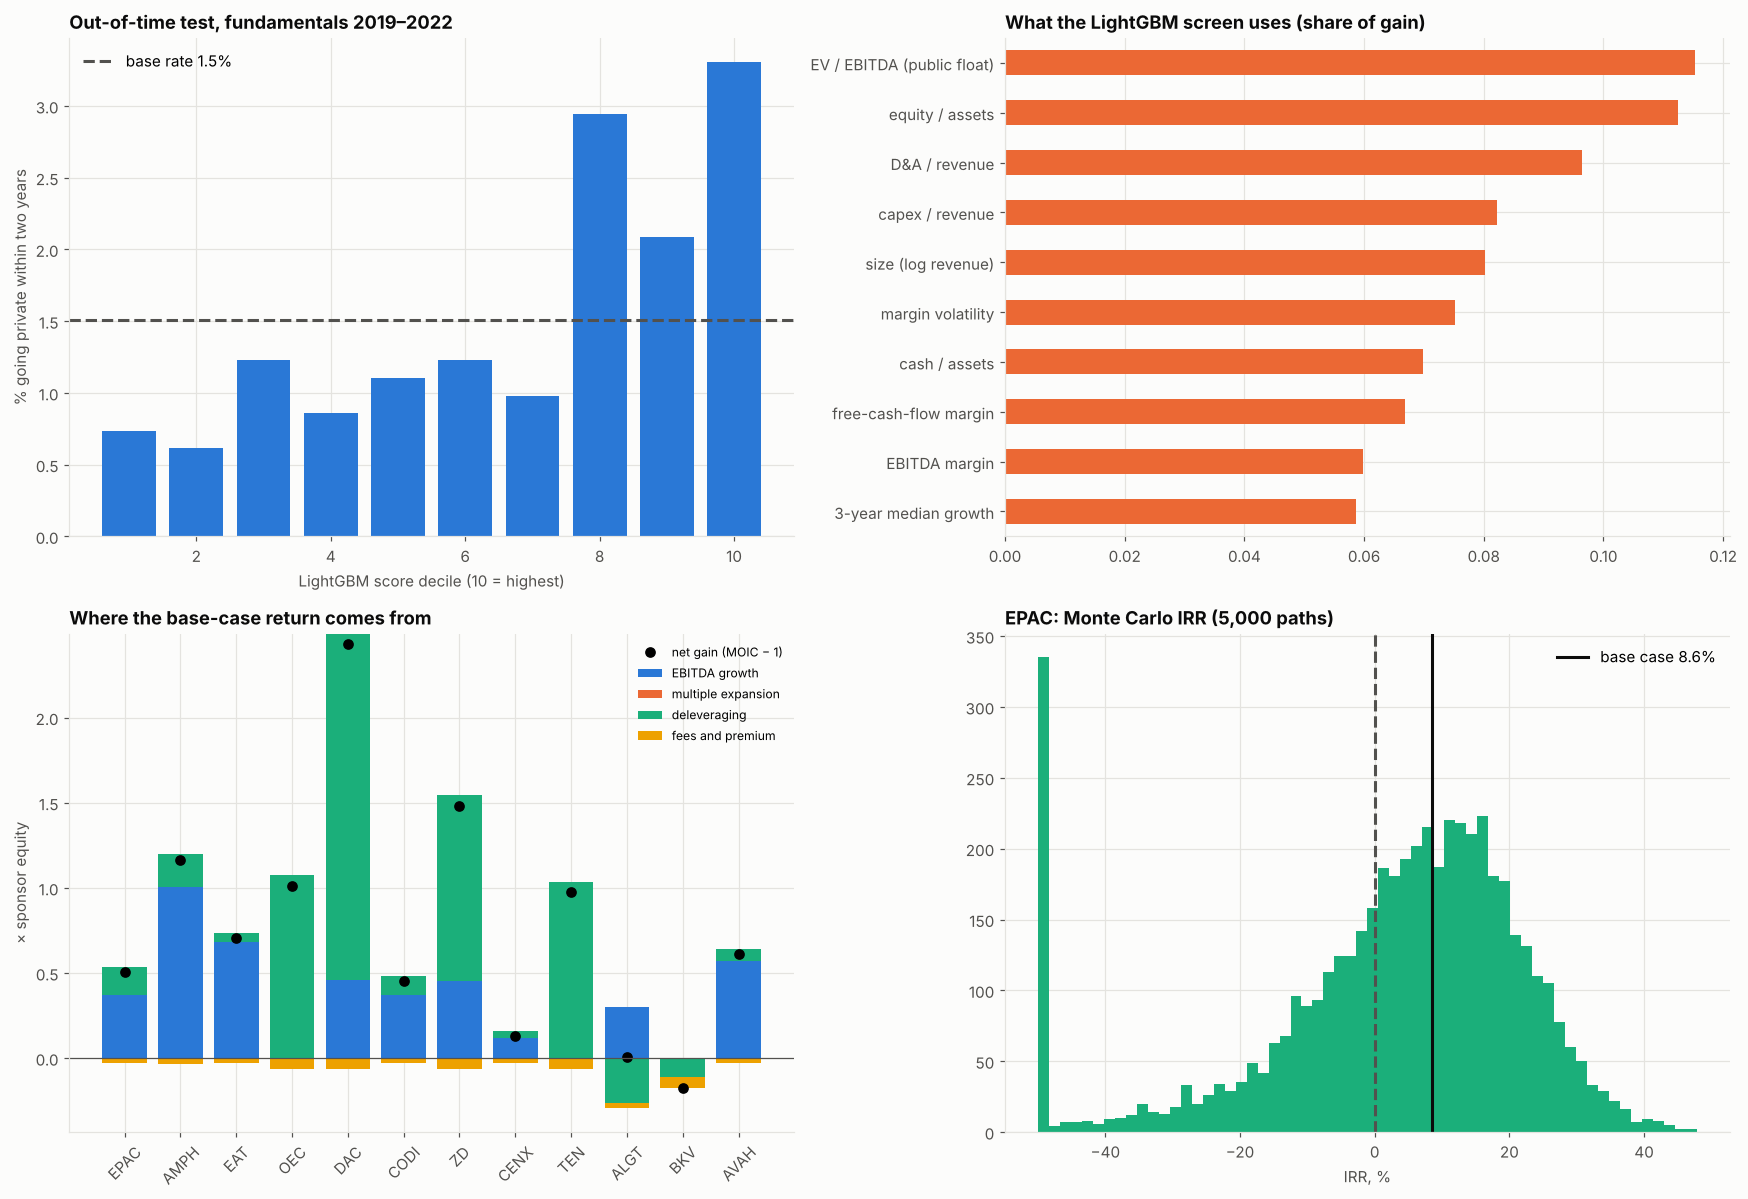

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(16, 11))
a = ax[0, 0]
rate = dec.groupby("decile", observed=True).label.mean()
a.bar(rate.index.astype(int), rate.values * 100, color=PALETTE[0])
a.axhline(
    y.mean() * 100, color=INK_2, ls="--", label=f"base rate {y.mean():.1%}"
)
a.set_xlabel("LightGBM score decile (10 = highest)")
a.set_ylabel("% going private within two years")
a.set_title(f"Out-of-time test, fundamentals {TEST_FIRST}–{TEST_LAST}")
a.legend()
a = ax[0, 1]
IMP.head(10)[::-1].plot.barh(ax=a, color=PALETTE[1])
a.set_title("What the LightGBM screen uses (share of gain)")
a = ax[1, 0]
att = TAB[
    ["EBITDA growth", "multiple expansion", "deleveraging", "fees and premium"]
]
bottom_pos = np.zeros(len(att))
bottom_neg = np.zeros(len(att))
for i, col in enumerate(att.columns):
    v = att[col].to_numpy()
    a.bar(
        att.index,
        np.where(v > 0, v, 0),
        bottom=bottom_pos,
        color=PALETTE[i],
        label=col,
    )
    a.bar(
        att.index, np.where(v < 0, v, 0), bottom=bottom_neg, color=PALETTE[i]
    )
    bottom_pos += np.where(v > 0, v, 0)
    bottom_neg += np.where(v < 0, v, 0)
a.plot(att.index, TAB.MOIC - 1, "ko", label="net gain (MOIC − 1)")
a.axhline(0, color=INK_2, lw=0.8)
a.set_ylabel("× sponsor equity")
a.set_title("Where the base-case return comes from")
a.tick_params(axis="x", rotation=45)
a.legend(fontsize=8)
a = ax[1, 1]
a.hist(np.clip(IRR_TOP, -0.5, 0.8) * 100, bins=60, color=PALETTE[2])
a.axvline(
    BASE[TOP]["irr"] * 100,
    color=INK,
    label=f"base case {BASE[TOP]['irr']:.1%}",
)
a.axvline(0, color=INK_2, ls="--")
a.set_xlabel("IRR, %")
a.set_title(f"{TOP}: Monte Carlo IRR ({N_SIMS:,} paths)")
a.legend()
fig.tight_layout()
save_fig(fig, "01_lbo")
plt.show()

In [11]:
dash = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        "Going-private rate by LightGBM decile (test)",
        "Candidates: base and Monte Carlo IRR",
    ),
)
dash.add_trace(
    go.Bar(
        x=rate.index.astype(int),
        y=rate.values,
        marker_color=PALETTE[0],
        showlegend=False,
    ),
    1,
    1,
)
for i, col in enumerate(["base IRR", "median IRR", "10th pct IRR"]):
    dash.add_trace(
        go.Bar(x=MCT.index, y=MCT[col], name=col, marker_color=PALETTE[i + 1]),
        1,
        2,
    )
dash.update_layout(
    height=600,
    width=1400,
    template="simple_white",
    title="Leveraged buyouts: screening and returns",
    barmode="group",
)
dash.update_yaxes(tickformat=".0%")
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 8. Reading the results and limitations

*SEC filings and market data are re-read weekly; every figure below comes from the run shown in this notebook (815 Schedule 13E-3 filings, 2011–2026; 34,531 company-years of XBRL fundamentals).*

**Who goes private.** 241 companies with usable financial statements filed a going-private schedule within two years of a fiscal year, a base rate of 1.2% a year. Compared with companies that stayed public (medians):
- **Cheap:** EV / EBITDA of 5.6 against 9.6 (public float standing in for market value).
- **Small:** revenue of about USD 0.5 billion against 1.1 billion.
- **Little net debt:** net debt / EBITDA of 0.0 against 0.3.
- **Not more cash-generative:** the free-cash-flow margin is the same (9%), and margins are slightly more volatile.

The textbook profile is half right. Low valuation and spare debt capacity matter, but going-private targets do not stand out for stable, high cash flows. Many are small companies for which a listing costs more than it brings.

**Screening, out of time** (fundamentals 2019–2022, filings 2020–2024; 123 targets in 8,152 company-years):

| | ROC AUC (90% interval) | Precision–recall AUC / base rate | Targets in top decile | Targets in top quintile |
|---|---|---|---|---|
| Classic LBO screen (logit, 4 criteria) | 0.55 (0.51–0.59) | 1.3× | 17% | 23% |
| **LightGBM (14 ratios)** | **0.65** (0.60–0.68) | **2.0×** | **22%** | **36%** |

- **Gradient boosting doubles the hit rate of a random list.** Its top decile went private at 3.3% against 0.7% in the bottom decile, and it finds 36% of all targets in a fifth of the market.
- **What it uses.** Valuation (12% of the gain), equity / assets (11%), depreciation intensity (10%) and capex (8%): asset-heavy, cheaply valued, conservatively financed companies. In the classic screen only valuation carries weight; the free-cash-flow margin and margin stability add almost nothing.
- **Going private stays hard to predict.** An AUC of 0.65 ranks well above chance, but most high-scoring companies stay public: a deal needs a willing buyer, financing and a board that agrees, none of which is in the accounts.

**LBO models at today's rates.** The term loan costs 7.6% (SOFR + 3.75%) and the notes 8.2% (10-year Treasury + high-yield spread). At those rates, the requirement that EBITDA cover interest twice limits debt to about 6.4 × EBITDA, just above the 6.0 × cap. Base case, five-year hold, exit at the entry multiple:

| Candidate | Entry EV / EBITDA | Debt / EBITDA | Sponsor equity / price | IRR | Gain from deleveraging (× equity) |
|---|---|---|---|---|---|
| Danaos | 5.1 | 3.6 | 31% | 28% | 2.0 |
| Ziff Davis | 6.1 | 4.3 | 31% | 20% | 1.1 |
| Amphastar | 14.5 | 6.0 | 59% | 17% | 0.2 |
| Orion | 5.7 | 4.0 | 31% | 15% | 1.1 |
| Enerpac Tool Group (top-ranked) | 18.0 | 6.0 | 67% | 9% | 0.2 |
| Brinker International | 17.5 | 6.0 | 66% | 11% | 0.1 |
| Allegiant Travel | 17.2 | 6.0 | 66% | 0% | −0.3 |

- **The entry multiple decides the deal.** At 5–8 × EBITDA, debt is capped by the 70% loan-to-value limit, and repaying it from cash flow produces most of the return (1–2 times the equity cheque). At 15–20 ×, debt can only be 6 × EBITDA, the sponsor must put up two-thirds of the price, and with no multiple expansion the IRR falls to 0–11%: the return of a lightly levered equity investment, not an LBO.
- **Enerpac, the screen's top pick,** is a good business (EBITDA margin 24%, free-cash-flow margin 18%) at a poor price for a buyout. In the model its leverage falls from 5.4 to 3.2 × EBITDA and interest cover rises from 2.2 to 3.3 ×, but the money multiple is only 1.5.

**Monte Carlo.** With revenue growth, margins and the exit multiple simulated from each company's history, the probability of losing money ranges from 27% (Ziff Davis, median IRR 17%, almost no risk of a cash shortfall) to 51–57% (Century Aluminum, Allegiant and BKV, whose cash flows are cyclical). Leverage turns volatility into losses: in the worst tenth of paths most candidates lose the whole equity cheque. This is why sponsors pay for stability, and why the cyclical names that a valuation screen flags are rarely bought.

**Limitations.**
- **Not all 13E-3 filings are sponsor buyouts.** Management buyouts, controlling-holder squeeze-outs and deregistrations of small companies are included; sponsor-backed LBOs of large companies are a minority of the sample.
- **Public float is not market value.** It excludes insiders' shares and is measured at mid-year, so valuation ratios are approximate. Companies with a controlling holder look cheaper than they are, which may help the screen find squeeze-outs.
- **Companies without XBRL facts** (before 2011, or filing in other formats) and those taken private before filing a 10-K in XBRL are missing.
- **Simplified LBO.** No management incentive equity, dividend recaps, add-on acquisitions or operational improvements beyond the company's own trend. Exiting at the entry multiple removes multiple expansion, historically a large part of buyout returns.
- **Candidate list.** Partnerships, financials, real estate and utilities are excluded mechanically, and some foreign issuers (shipping companies filing 10-Ks) remain. The list is an illustration of the method, not investment advice.

In [12]:
RES.to_csv(OUT_DIR / "screen_out_of_time.csv")
DEC.to_csv(OUT_DIR / "lightgbm_deciles.csv")
TAB.to_csv(OUT_DIR / "lbo_base_case.csv")
MCT.to_csv(OUT_DIR / "lbo_monte_carlo.csv")
r0["rows"].to_csv(OUT_DIR / f"lbo_model_{TOP}.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_lbo.png, dashboard.html, dashboard.png, lbo_base_case.csv, lbo_model_EPAC.csv, lbo_monte_carlo.csv, lightgbm_deciles.csv, screen_out_of_time.csv


## References

- U.S. Securities and Exchange Commission. EDGAR full-text index of filings (form.idx) and XBRL frames API. https://www.sec.gov/search-filings/edgar-application-programming-interfaces
- U.S. Securities and Exchange Commission. Rule 13e-3 and Schedule 13E-3 (going-private transactions). https://www.sec.gov/rules-regulations/staff-guidance/compliance-disclosure-interpretations/going-private-transactions-exchange-act-rule-13e-3-schedule-13e-3
- Federal Reserve Bank of St. Louis. FRED series SOFR, DGS10 and BAMLH0A0HYM2 (ICE BofA US High Yield Index Option-Adjusted Spread). https://fred.stlouisfed.org/
- Kaplan, S. N., & Strömberg, P. (2009). Leveraged buyouts and private equity. *Journal of Economic Perspectives*, 23(1), 121–146.
- Axelson, U., Jenkinson, T., Strömberg, P., & Weisbach, M. S. (2013). Borrow cheap, buy high? The determinants of leverage and pricing in buyouts. *Journal of Finance*, 68(6), 2223–2267.
- Guo, S., Hotchkiss, E. S., & Song, W. (2011). Do buyouts (still) create value? *Journal of Finance*, 66(2), 479–517.
- Achleitner, A.-K., Braun, R., Engel, N., Figge, C., & Tappeiner, F. (2010). Value creation drivers in private equity buyouts: Empirical evidence from Europe. *Journal of Private Equity*, 13(2), 17–27.
- Rosenbaum, J., & Pearl, J. (2020). *Investment Banking: Valuation, LBOs, M&A, and IPOs* (3rd ed.). Wiley.
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. In *Advances in Neural Information Processing Systems 30*.